# 01 — Data: EDA and quality checks

Exploration of the processed ONS tables (`uv run ons ingest` → `uv run ons build`). All logic is in
`ons_energy`; this notebook only explores and plots.

1. Load by subsystem: history, growth, daily profile, holiday effect
2. Generation mix, stored energy (EAR) and natural inflow (ENA)
3. Data quality: manifest, imputation, consistency between datasets, load API

In [1]:
%matplotlib inline
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from ons_energy.calendar.holidays import daily_calendar
from ons_energy.data import quality as Q
from ons_energy.utils.io import PROCESSED_DIR
from ons_energy.viz import forecast_plots as F
from ons_energy.viz.style import EVENT_FILL, SERIES, apply_style

apply_style()
pd.set_option("display.precision", 2)

## 1. Load by subsystem
ONS `curva-carga` (MWmed, Brasília wall clock). The load definition changed twice — Mar/2021 (adds the
forecast of non-dispatched generation) and 29/04/2023 (adds distributed solar, MMGD) — so the
forecasting models carry regime dummies.

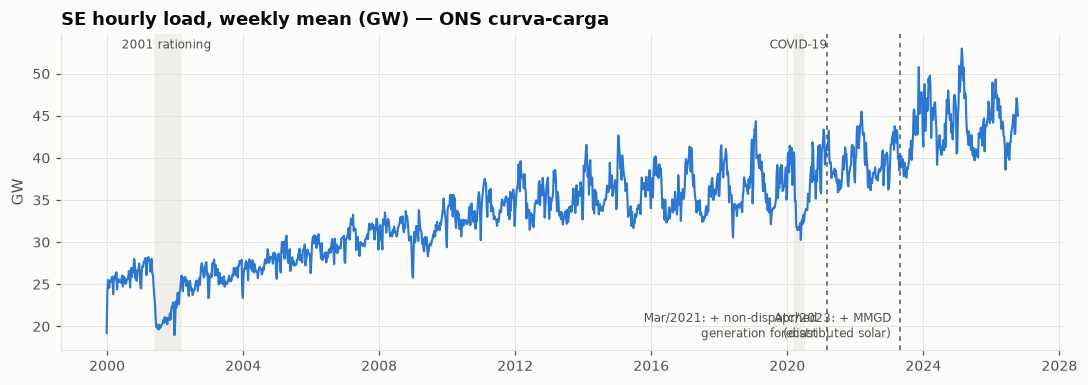

In [2]:
fig = F.load_history("SE")

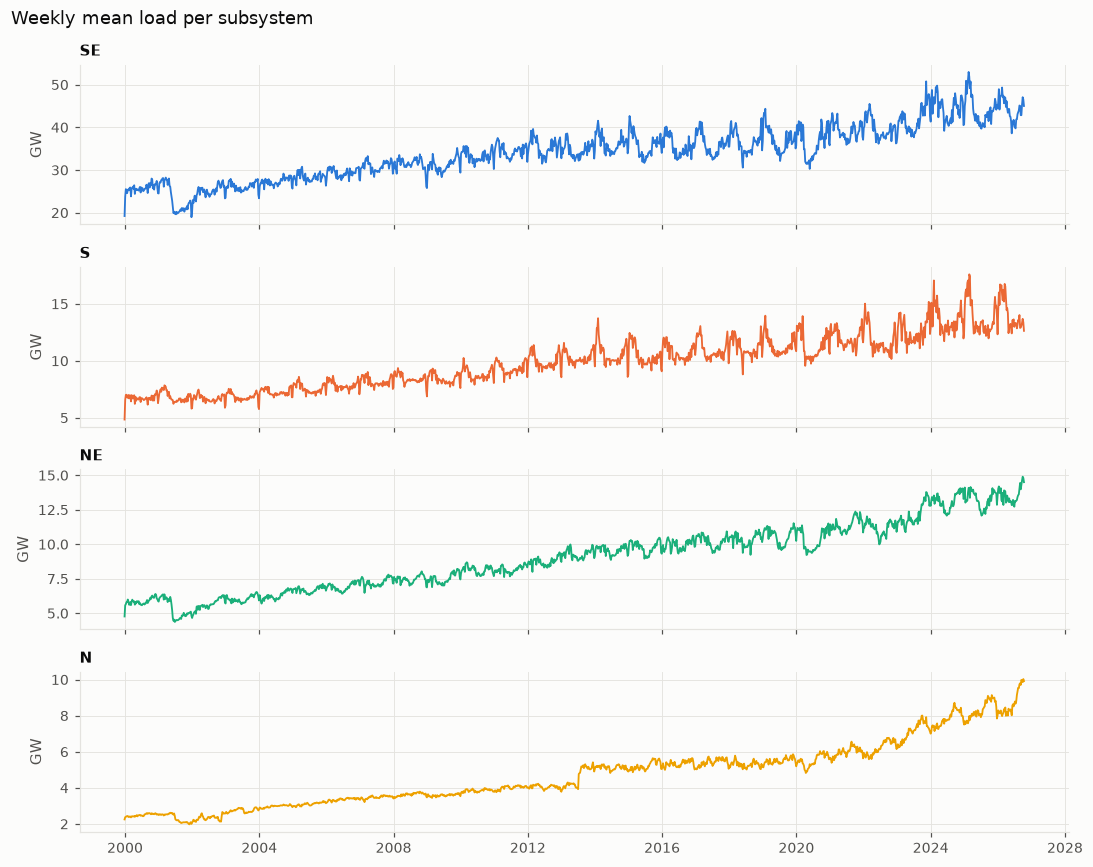

In [3]:
load = pl.read_parquet(PROCESSED_DIR / "load_hourly.parquet")
weekly = load.group_by_dynamic("ts_local", every="1w", group_by="subsystem").agg(pl.col("load_mw").mean()).to_pandas()
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, sub, c in zip(axes, ["SE", "S", "NE", "N"], SERIES):
    g = weekly[weekly.subsystem == sub]
    ax.plot(g.ts_local, g.load_mw / 1000, color=c, linewidth=1.2)
    ax.set_title(sub, fontsize=10)
    ax.set_ylabel("GW")
fig.suptitle("Weekly mean load per subsystem", x=0.01, ha="left")
fig.tight_layout()

### Share of the SIN load by subsystem (%)

In [4]:
yr = load.group_by("subsystem", pl.col("ts_local").dt.year().alias("year")).agg(pl.col("load_mw").mean()).to_pandas()
piv = yr.pivot(index="year", columns="subsystem", values="load_mw")
(piv.div(piv.sum(axis=1), axis=0) * 100).round(1).loc[[2000, 2010, 2020, 2025]]

subsystem,N,NE,S,SE
year,,,,
2000,6.1,14.4,16.5,63.0
2010,7.1,15.1,16.3,61.5
2020,8.7,16.2,17.8,57.3
2025,10.4,16.7,17.3,55.6


### Daily profile by day of week (SE/CO, 2025)

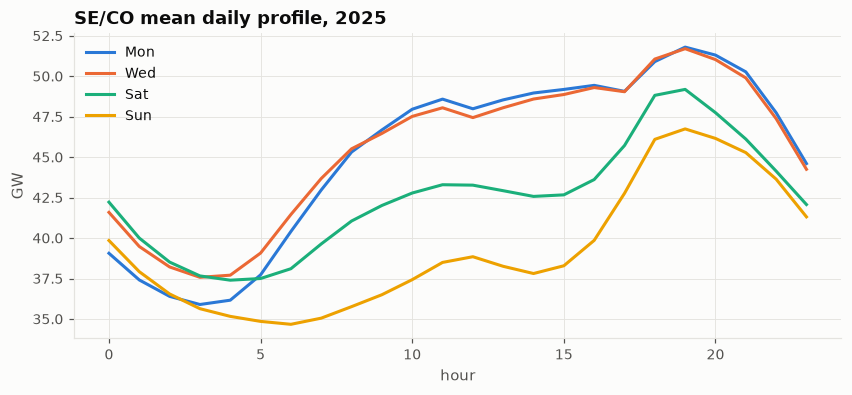

In [5]:
se = load.filter((pl.col("subsystem") == "SE") & (pl.col("ts_local").dt.year() == 2025)).to_pandas()
se["hour"], se["dow"] = se.ts_local.dt.hour, se.ts_local.dt.dayofweek
prof = se.groupby(["dow", "hour"]).load_mw.mean().unstack(0) / 1000
fig, ax = plt.subplots(figsize=(9, 3.6))
for d, c in zip([0, 2, 5, 6], SERIES):
    ax.plot(prof.index, prof[d], color=c, label=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][d])
ax.set_xlabel("hour")
ax.set_ylabel("GW")
ax.legend()
ax.set_title("SE/CO mean daily profile, 2025");

### Holiday effect
SE/CO daily load on national holidays and Carnival relative to the same weekday one week earlier.

In [6]:
last_day = load["ts_local"].max().date()
cal = daily_calendar(date(2015, 1, 1), last_day, "SE").to_pandas().set_index("date")
d = (load.filter(pl.col("subsystem") == "SE").group_by(pl.col("ts_local").dt.date().alias("date"))
     .agg(pl.col("load_mw").mean()).to_pandas().set_index("date").load_mw)
cal.index, d.index = pd.to_datetime(cal.index), pd.to_datetime(d.index)
hol = cal.index[cal.is_national_holiday | cal.is_carnival]
prev = hol.shift(-7, freq="D")
ok = hol.isin(d.index) & prev.isin(d.index)
ratio = pd.Series(d[hol[ok]].to_numpy() / d[prev[ok]].to_numpy(), index=hol[ok])
names = cal.loc[ratio.index, "holiday_name"].fillna("Carnaval")
ratio.groupby(names.values).mean().sub(1).mul(100).round(1).sort_values().to_frame("load change vs. previous week (%)")

,load change vs. previous week (%)
Natal,-19.0
Sexta-feira Santa,-18.2
Dia do Trabalhador,-12.1
Finados,-12.1
Nossa Senhora Aparecida,-9.5
Carnaval,-9.3
Tiradentes,-9.1
Independência do Brasil,-8.5
Proclamação da República,-4.6
Dia Nacional de Zumbi e da Consciência Negra,-4.5


## 2. Generation mix, EAR and ENA
Balance per subsystem (nuclear split out of thermal) and daily hydro indicators.

,hydro,thermal,nuclear,wind,solar
year,,,,,
2000,94.2,4.1,1.7,0.0,0.0
2010,89.0,7.7,3.1,0.3,0.0
2015,71.1,22.6,2.7,3.6,0.0
2020,73.0,13.7,2.5,9.8,0.9
2025,57.7,10.5,2.3,16.5,13.1
2026,59.2,9.4,2.0,15.0,14.5


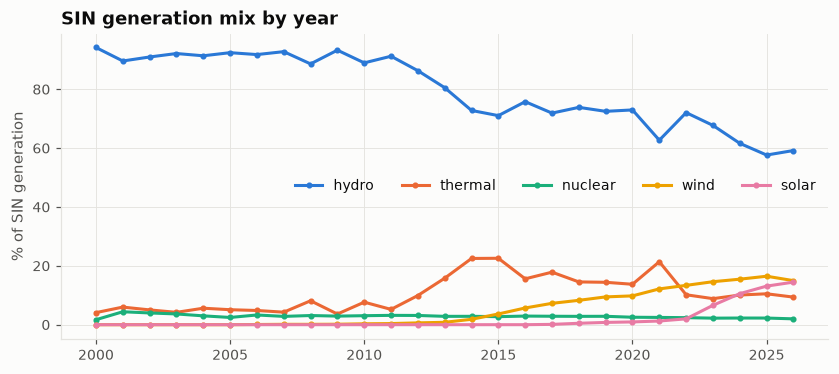

In [7]:
bal = pl.read_parquet(PROCESSED_DIR / "balance_hourly.parquet").filter(pl.col("subsystem") == "SIN")
src = ["hydro", "thermal", "nuclear", "wind", "solar"]
yr = bal.group_by(pl.col("ts_local").dt.year().alias("year")).agg([pl.col(s).mean() for s in src]).sort("year").to_pandas().set_index("year")
share = yr.div(yr.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
for s, c in zip(src, SERIES):
    ax.plot(share.index, share[s], color=c, marker="o", ms=3, label=s)
ax.set_ylabel("% of SIN generation")
ax.legend(ncol=5)
ax.set_title("SIN generation mix by year")
share.round(1).loc[[2000, 2010, 2015, 2020, 2025, 2026]]

### Stored energy (EAR) and natural inflow (ENA) — the hydro crises (2001, 2014–15, 2021 shaded)

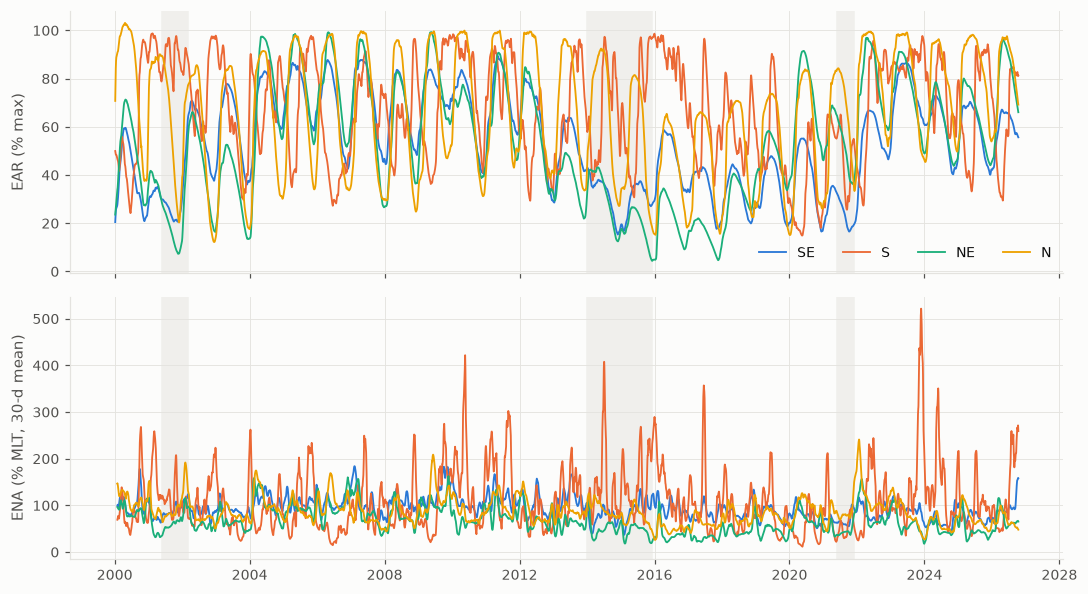

In [8]:
hyd = pl.read_parquet(PROCESSED_DIR / "hydro_daily.parquet").to_pandas()
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for sub, c in zip(["SE", "S", "NE", "N"], SERIES):
    g = hyd[hyd.subsystem == sub].set_index("date")
    axes[0].plot(g.index, g.ear_pct.rolling(7).mean(), color=c, linewidth=1.2, label=sub)
    axes[1].plot(g.index, g.ena_pct_mlt.rolling(30).mean(), color=c, linewidth=1.2, label=sub)
axes[0].set_ylabel("EAR (% max)")
axes[1].set_ylabel("ENA (% MLT, 30-d mean)")
axes[0].legend(ncol=4)
for ax in axes:
    for a, b in (("2001-06-01", "2002-02-28"), ("2014-01-01", "2015-11-30"), ("2021-06-01", "2021-11-30")):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=EVENT_FILL, zorder=0)
fig.tight_layout()

### Wind/solar ramp-up (MWmed) — why static PCA references age fast

In [9]:
b4 = pl.read_parquet(PROCESSED_DIR / "balance_hourly.parquet").filter(pl.col("subsystem") != "SIN")
v = b4.group_by("subsystem", pl.col("ts_local").dt.year().alias("year")).agg(pl.col("wind").mean(), pl.col("solar").mean()).to_pandas()
v.pivot(index="year", columns="subsystem", values=["wind", "solar"]).round(0).loc[[2010, 2016, 2019, 2022, 2024, 2026]]

wind                         solar                        
subsystem      N       NE      S     SE      N      NE       S      SE
year                                                                  
2010         0.0    124.0   41.0    0.0    0.0     0.0     0.0     0.0
2016         0.0   2961.0  538.0    0.0    0.0     2.0     0.0     0.0
2019       188.0   5264.0  642.0    0.0    0.0   327.0     0.0   174.0
2022       183.0   8381.0  699.0    7.0    1.0   972.0     1.0   406.0
2024       204.0  11300.0  728.0    6.0  422.0  2821.0  1074.0  4033.0
2026       184.0  11260.0  572.0  119.0  704.0  3834.0  1327.0  5819.0

## 3. Data quality
Computed by `ons_energy.data.quality` on the processed tables.

### Raw files (manifest: ETag / sha256 / fetch time)

In [10]:
Q.manifest_summary()

,dataset,files,mb,first_year,last_year,last_fetch
0,balance_hourly,27,55.3,2000.0,2026.0,2026-10-15 02:55:10.104550+00:00
1,ear_daily,27,0.9,2000.0,2026.0,2026-10-15 03:05:43.611341+00:00
2,ena_daily,27,2.6,2000.0,2026.0,2026-10-15 03:05:56.508535+00:00
3,generation_plant_hourly,80,733.1,2000.0,2026.0,2026-10-15 03:05:32.038536+00:00
4,load_hourly,27,12.4,2000.0,2026.0,2026-10-15 02:54:19.431914+00:00
5,load_interruptions,1,0.2,NaN,NaN,2026-10-15 03:05:57.349764+00:00


### Imputation
Rows created/filled by the cleaning: missing spring-forward DST hours (2000–2018) and three whole
missing days (2013-12-01, 2014-02-01, 2015-04-09) filled with the same hour of the previous week.

In [11]:
Q.imputation_summary()

,table,subsystem,rows,imputed,imputed_pct
4,balance_hourly,N,234792,91,0.04
5,balance_hourly,NE,234792,91,0.04
6,balance_hourly,S,234792,90,0.04
8,balance_hourly,SE,234792,91,0.04
7,balance_hourly,SIN,234792,6691,2.85
10,hydro_daily,N,9783,0,0.00
11,hydro_daily,NE,9783,0,0.00
12,hydro_daily,S,9783,0,0.00
9,hydro_daily,SE,9783,0,0.00
0,load_hourly,N,234792,91,0.04


In [12]:
Q.dst_days().head(10)  # one imputed 00:00 per DST start

,day,len
0,2000-10-08,1
1,2001-10-14,1
2,2002-11-03,1
3,2003-10-19,1
4,2004-11-02,1
5,2005-10-16,1
6,2006-11-05,1
7,2007-10-14,1
8,2008-10-19,1
9,2009-10-18,1


### Consistency between datasets

In [13]:
Q.balance_vs_load()  # curva-carga vs balanço load (MW)

{'mean_abs_diff_mw': 0.0587971684917753, 'share_gt_1mw': 0.000239573750383318}

In [14]:
Q.thermal_includes_nuclear()  # balance 'thermal' includes Angra 1/2 -> split out

{'mae_vs_thermal_plus_nuclear': 0.036170778872379176,
 'mae_vs_thermal_only': 1804.711786070404}

In [15]:
Q.reconciliation(2025).round(1)  # balance vs sum of plants

,subsystem,source,balance_mean,plants_mean,mae
0,SE,hydro,26999.7,26989.3,10.5
1,SE,thermal,4455.5,4455.5,0.0
2,SE,wind,68.7,6.2,62.5
3,SE,solar,5257.4,5257.4,0.0
4,SE,nuclear,1804.7,1804.7,0.0
5,S,hydro,8293.5,8293.5,0.0
6,S,thermal,1065.2,1065.2,0.0
7,S,wind,698.8,698.8,0.0
8,S,solar,1301.0,1301.0,0.0
9,S,nuclear,0.0,0.0,0.0


### Load API: alignment and definitions
Lag 0 has the highest correlation, so the half-hour (UTC, end of interval) → local hour mapping is
right; the API "carga global" runs ~0.9% above curva-carga by definition.

In [16]:
Q.api_alignment().round(4)

,lag_h,corr,mean_ratio
0,-2,0.88,1.01
1,-1,0.96,1.01
2,0,0.99,1.01
3,1,0.96,1.01
4,2,0.88,1.01


In [17]:
Q.programmed_vs_actual()  # ONS programmed load bias vs curva-carga (test period)

{'bias_mw': 640.0318157215982,
 'bias_pct': 1.5217982437695012,
 'mape': 2.7209483809024966,
 'n_hours': 24384}

In [18]:
Q.methodology_levels().round(0).tail(24)

,ts_local,load,mmgd,programmed
58,2024-11-01,44153.0,3347.0,44172.0
59,2024-12-01,44731.0,3596.0,44999.0
60,2025-01-01,46754.0,3865.0,46654.0
61,2025-02-01,51069.0,4235.0,50670.0
62,2025-03-01,48586.0,3983.0,49428.0
63,2025-04-01,44297.0,3223.0,45125.0
64,2025-05-01,41856.0,3235.0,42641.0
65,2025-06-01,41059.0,3012.0,41319.0
66,2025-07-01,40357.0,3379.0,40786.0
67,2025-08-01,41177.0,3931.0,41678.0
